### 02 — Spatiotemporal Analysis

This notebook aggregates cleaned AIS observations by **GFW spatial cell × month × year** and establishes the temporal/spatial summaries needed before regional trend analysis.

### Important preprocessing note

The source dataset used for this analysis was previously filtered to retain observations with fishing activity. Therefore, the current dataset represents fishing-active observations rather than all vessel presence/effort observations.

Consequently, `fishing_hours` is the primary measure of fishing effort. `fishing_ratio` is supplementary and should not be interpreted as the proportion of all vessel time spent fishing.

### 1. Imports

In [1]:
from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
pd.set_option("display.max_columns", None)
pd.set_option("display.max_rows", 100)

### 2. Load cleaned dataset

In [2]:
DATA_FILE = Path("../outputs/processed/ais_cleaned.parquet")
ais = pd.read_parquet(DATA_FILE)
print("Shape:", ais.shape)
print("Date range:", ais.date.min(), "→", ais.date.max())
print("Unique vessels:", ais.mmsi.nunique())
print("Unique spatial cells:", ais[["cell_ll_lat","cell_ll_lon"]].drop_duplicates().shape[0])
print("Latitude:", ais.cell_ll_lat.min(), "→", ais.cell_ll_lat.max())
print("Longitude:", ais.cell_ll_lon.min(), "→", ais.cell_ll_lon.max())

Shape: (730488, 11)
Date range: 2012-02-15 00:00:00 → 2024-12-31 00:00:00
Unique vessels: 1930
Unique spatial cells: 23846
Latitude: -29.2 → 40.0
Longitude: 32.0 → 161.9


### 3. Aggregate by spatial cell × month × year

In [3]:
monthly_cell = ais.groupby(["year","month","cell_ll_lat","cell_ll_lon"], as_index=False).agg(total_hours=("hours","sum"), fishing_hours=("fishing_hours","sum"), active_vessels=("mmsi","nunique"), active_days=("date","nunique"))
print("Aggregated shape:", monthly_cell.shape)
display(monthly_cell.head())

Aggregated shape: (149693, 8)


,year,month,cell_ll_lat,cell_ll_lon,total_hours,fishing_hours,active_vessels,active_days
0,2012,2,11.7,74.9,7.6377,3.1729,1,2
1,2012,2,12.5,74.6,3.7586,3.7586,1,1
2,2012,2,12.5,74.7,6.0836,6.0836,1,1
3,2012,2,12.6,74.6,2.9963,2.9963,1,1
4,2012,2,12.7,74.6,1.7338,1.7338,1,1


### 4. Supplementary fishing ratio

In [4]:
monthly_cell["fishing_ratio"] = np.where(monthly_cell.total_hours > 0, monthly_cell.fishing_hours/monthly_cell.total_hours, np.nan)
display(monthly_cell.fishing_ratio.describe())
ratio_one = int((monthly_cell.fishing_ratio == 1).sum())
print("Ratio exactly 1:", ratio_one)
print("Percentage:", round(100*ratio_one/len(monthly_cell),2), "%")
print("Groups where fishing_hours > total_hours:", int((monthly_cell.fishing_hours > monthly_cell.total_hours).sum()))

count    149693.000000
mean          0.893841
std           0.206408
min           0.000679
25%           0.891866
50%           1.000000
75%           1.000000
max           1.000000
Name: fishing_ratio, dtype: float64

Ratio exactly 1: 84318
Percentage: 56.33 %
Groups where fishing_hours > total_hours: 0


### 5. Overall yearly fishing effort

In [5]:
yearly_summary = monthly_cell.groupby("year", as_index=False).agg(fishing_hours=("fishing_hours","sum"), total_hours=("total_hours","sum"), active_vessels=("active_vessels","sum"), active_days=("active_days","sum"))
display(yearly_summary)

,year,fishing_hours,total_hours,active_vessels,active_days
0,2012,3144.5448,3.304245e+03,474,552
1,2013,1101.3706,1.235772e+03,157,208
2,2014,3073.1638,3.410050e+03,480,686
3,2015,7834.2535,8.734885e+03,840,1438
4,2016,7963.5265,9.158479e+03,1522,2168
5,2017,21215.1131,2.529884e+04,4085,4640
6,2018,65335.0711,7.563275e+04,11185,10740
7,2019,81839.8844,9.213733e+04,13441,14052
8,2020,41358.3002,4.547868e+04,6245,6401
9,2021,220120.4358,2.574390e+05,33950,28984


### 6. Monthly fishing effort

In [6]:
monthly_summary = monthly_cell.groupby("month", as_index=False).agg(fishing_hours=("fishing_hours","sum"), total_hours=("total_hours","sum"))
display(monthly_summary)

,month,fishing_hours,total_hours
0,1,232550.1543,267015.3572
1,2,365837.6705,418359.6529
2,3,381069.5686,437789.8519
3,4,318927.7074,361981.7386
4,5,235402.6993,260774.2793
5,6,60354.7702,65891.8728
6,7,68860.3703,75062.9823
7,8,227186.4443,252689.3022
8,9,242645.3363,274671.3830
9,10,276184.1021,314583.2674


### 7. Year × month fishing-effort matrix

In [7]:
year_month_effort = monthly_cell.groupby(["year","month"])["fishing_hours"].sum().unstack(fill_value=np.nan)
display(year_month_effort)

month,1,2,3,4,5,6,7,8,9,10,11,12
year,,,,,,,,,,,,
2012,NaN,92.0560,175.9118,539.8330,577.3371,546.1355,326.8526,342.6282,217.0065,23.0406,222.3883,81.3552
2013,NaN,NaN,NaN,249.1488,9.0225,241.5940,256.7924,231.3149,113.4980,NaN,NaN,NaN
2014,NaN,NaN,NaN,531.1249,553.7506,717.9499,595.9957,322.0917,166.7615,8.6635,53.9471,122.8789
2015,229.8629,1010.5830,958.6129,1653.4975,1562.4494,630.2129,526.8822,208.0467,168.1915,319.6079,348.7292,217.5774
2016,166.6541,554.3262,77.0449,388.9689,160.4714,536.4500,289.4339,299.2633,364.8218,1191.9869,1665.5817,2268.5234
2017,2863.1122,1955.2810,2257.2208,1801.8711,2628.5535,156.0603,30.6711,248.9745,740.0752,NaN,2960.7147,5572.5787
2018,4445.4666,7640.8200,7473.9666,7362.9393,4443.8053,96.3379,295.5387,723.1087,7119.9081,9505.3645,10670.7455,5557.0699
2019,16280.5635,13184.5292,16446.8121,8119.8109,8126.7660,690.3570,1112.7706,3527.3149,678.2889,1930.5700,6317.1053,5424.9960
2020,9239.1041,10665.3492,9492.8779,75.2960,57.3478,530.9453,200.7082,1080.4958,2078.3647,2725.9653,5211.8459,NaN


### 8. Annual effort plot

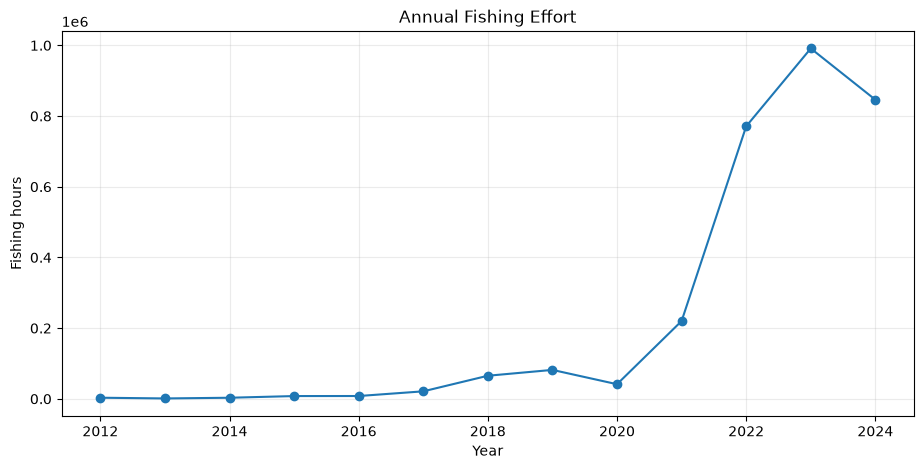

In [8]:
plt.figure(figsize=(11,5))
plt.plot(yearly_summary.year, yearly_summary.fishing_hours, marker="o")
plt.xlabel("Year"); plt.ylabel("Fishing hours"); plt.title("Annual Fishing Effort"); plt.grid(alpha=0.25); plt.show()

### 9. Monthly seasonality plot

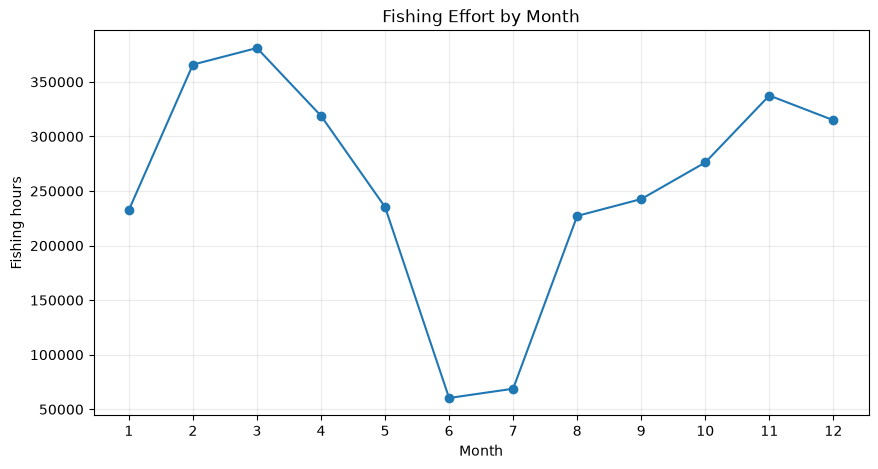

In [9]:
plt.figure(figsize=(10,5))
plt.plot(monthly_summary.month, monthly_summary.fishing_hours, marker="o")
plt.xticks(range(1,13)); plt.xlabel("Month"); plt.ylabel("Fishing hours"); plt.title("Fishing Effort by Month"); plt.grid(alpha=0.25); plt.show()

### 10. Spatial summary

In [10]:
spatial_summary = monthly_cell.groupby(["cell_ll_lat","cell_ll_lon"], as_index=False).agg(total_fishing_hours=("fishing_hours","sum"), total_hours=("total_hours","sum"), active_vessels=("active_vessels","sum"), active_months=("month","count"))
display(spatial_summary.sort_values("total_fishing_hours", ascending=False).head(20))

,cell_ll_lat,cell_ll_lon,total_fishing_hours,total_hours,active_vessels,active_months
10389,12.8,74.6,22251.9623,26798.2985,3413,53
10199,12.7,74.6,19797.9999,23277.4537,2820,48
10009,12.6,74.7,17814.9795,21519.3890,2216,43
10200,12.7,74.7,16075.3184,20101.9084,2642,43
10593,12.9,74.5,15299.7211,17253.8147,2364,46
10794,13.0,74.5,14779.8596,16330.4397,2343,48
10008,12.6,74.6,14258.7287,16602.9253,1925,47
10594,12.9,74.6,14179.4949,17098.1450,2999,49
10991,13.1,74.5,14160.6571,15774.4992,2168,45
10795,13.0,74.6,13833.8764,16465.2440,2524,48


### 11. Spatial fishing-effort map

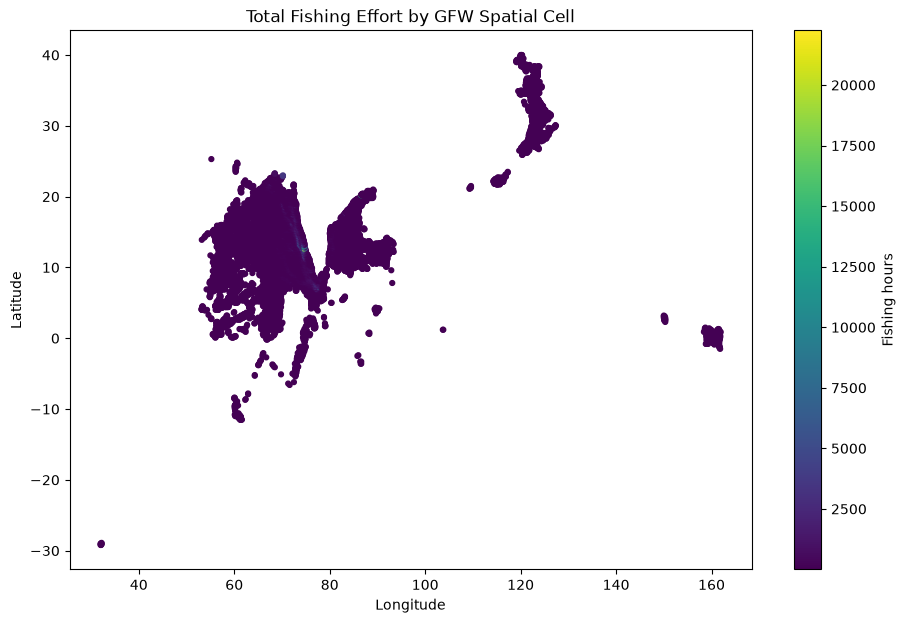

In [11]:
plt.figure(figsize=(11,7))
plt.scatter(spatial_summary.cell_ll_lon, spatial_summary.cell_ll_lat, c=spatial_summary.total_fishing_hours, s=12)
plt.xlabel("Longitude"); plt.ylabel("Latitude"); plt.title("Total Fishing Effort by GFW Spatial Cell")
plt.colorbar(label="Fishing hours"); plt.show()

### 12. Highest-effort cells

In [12]:
top_cells = spatial_summary.sort_values("total_fishing_hours", ascending=False).head(25).reset_index(drop=True)
display(top_cells)

,cell_ll_lat,cell_ll_lon,total_fishing_hours,total_hours,active_vessels,active_months
0,12.8,74.6,22251.9623,26798.2985,3413,53
1,12.7,74.6,19797.9999,23277.4537,2820,48
2,12.6,74.7,17814.9795,21519.3890,2216,43
3,12.7,74.7,16075.3184,20101.9084,2642,43
4,12.9,74.5,15299.7211,17253.8147,2364,46
5,13.0,74.5,14779.8596,16330.4397,2343,48
6,12.6,74.6,14258.7287,16602.9253,1925,47
7,12.9,74.6,14179.4949,17098.1450,2999,49
8,13.1,74.5,14160.6571,15774.4992,2168,45
9,13.0,74.6,13833.8764,16465.2440,2524,48


### 13. Year × spatial cell effort

In [13]:
yearly_cell = monthly_cell.groupby(["year","cell_ll_lat","cell_ll_lon"], as_index=False).agg(fishing_hours=("fishing_hours","sum"), total_hours=("total_hours","sum"), active_vessels=("active_vessels","sum"), active_days=("active_days","sum"))
print("Year × cell rows:", len(yearly_cell))
display(yearly_cell.head())

Year × cell rows: 56591


,year,cell_ll_lat,cell_ll_lon,fishing_hours,total_hours,active_vessels,active_days
0,2012,8.4,74.5,2.4286,2.4286,1,1
1,2012,8.4,74.6,1.8550,1.8550,1,1
2,2012,8.5,74.5,0.2747,0.2747,1,1
3,2012,8.6,74.5,8.6641,8.6641,1,1
4,2012,8.7,74.5,2.2636,2.2636,1,1


### 14. Export analysis datasets

In [14]:
ANALYSIS_DIR = Path("../outputs/analysis")
ANALYSIS_DIR.mkdir(parents=True, exist_ok=True)
monthly_cell.to_parquet(ANALYSIS_DIR/"monthly_cell.parquet", index=False)
yearly_cell.to_parquet(ANALYSIS_DIR/"yearly_cell.parquet", index=False)
spatial_summary.to_parquet(ANALYSIS_DIR/"spatial_summary.parquet", index=False)
yearly_summary.to_csv(ANALYSIS_DIR/"yearly_summary.csv", index=False)
monthly_summary.to_csv(ANALYSIS_DIR/"monthly_summary.csv", index=False)
print("Analysis datasets saved to:", ANALYSIS_DIR.resolve())

Analysis datasets saved to: D:\ResearchPapers\AIS_Data_Analysis\outputs\analysis


### 15. Interpretation boundary

This notebook measures **AIS-derived fishing effort**, not fish biomass, catch, or true biological productivity. A decrease in `fishing_hours` therefore means a decrease in observed fishing effort; it does **not by itself prove** that fish productivity declined.

The next notebook should test whether fishing effort shows statistically meaningful regional trends and identify cells that are increasing, decreasing, or stable.